# DENV E-gene phylogeny (South Asia)
Kaggle notebook. Needs `lineage_assigned.csv` attached as a dataset (or in /kaggle/working) and Internet ON.
Set SEROTYPE in the first code cell (DENV-3 first, then rerun for DENV-2).

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "biopython"], check=False)
import os, glob, time, re, shutil, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from Bio import Entrez, SeqIO, Phylo
from Bio.Seq import Seq
from Bio.Align import PairwiseAligner
from io import StringIO

Entrez.email = "mdabusayemedu@gmail.com"
SEROTYPE = "DENV-3"          # change to DENV-2 for the second run
MIN_YEAR = 2015
CAP_PER_GROUP = 6            # max sequences per country x lineage x year
MAX_TIPS = 400
MIN_E_COVER = 0.90           # fraction of reference E that must be covered
REF = {"DENV-1": ("NC_001477", 935, 2419), "DENV-2": ("NC_001474", 937, 2421),
       "DENV-3": ("NC_001475", 935, 2413), "DENV-4": ("NC_002640", 939, 2423)}
OUT = "out_robust"; os.makedirs(OUT, exist_ok=True)
random.seed(1); np.random.seed(1)

def find(name):
    for root in ["/kaggle/working", "/kaggle/input"]:
        hits = glob.glob(f"{root}/**/{name}", recursive=True)
        if hits: return hits[0]
    raise FileNotFoundError(name + " not found. Attach it as a dataset.")
df = pd.read_csv(find("lineage_assigned.csv"))
# Remove accessions listed twice under different countries: keep the row whose country matches geo
df["_m"] = [str(c).lower() in str(g).lower() for c, g in zip(df.country, df.geo)]
df = df.sort_values("_m", ascending=False).drop_duplicates("acc").drop(columns="_m").reset_index(drop=True)
print(df.shape); print(df.columns.tolist())

(2509, 9)
['country', 'serotype', 'acc', 'length', 'year', 'geo', 'type', 'lineage', 'window']


In [2]:
# Column check (serotype labels differ between files)
print(df.serotype.unique()[:10])
print(df.type.value_counts())

[1 4 3 2]
type
E-gene sized            1479
near-complete genome    1030
Name: count, dtype: int64


In [3]:
# Select usable records and subsample evenly across country x lineage x year
d = df[df.serotype.astype(str) == SEROTYPE.split("-")[1]]
d = d[(d.year >= MIN_YEAR) & (d.type.isin(["near-complete genome", "E-gene sized"])) & d.lineage.notna()]
print("candidates:", len(d)); print(d.country.value_counts())
parts = []
for _, g in d.groupby(["country", "lineage", "year"]):
    parts.append(g.sample(min(len(g), CAP_PER_GROUP), random_state=1))
sub = pd.concat(parts)
if len(sub) > MAX_TIPS:
    frac = MAX_TIPS / len(sub)
    sub = pd.concat([g.sample(max(1, int(len(g) * frac)), random_state=1) for _, g in sub.groupby("country")])
sub = sub.reset_index(drop=True)
print("selected:", len(sub)); print(sub.country.value_counts())
assert len(sub) > 30, "too few sequences selected"

candidates: 687
country
India         344
Bangladesh    193
Sri Lanka      73
Bhutan         44
Nepal          23
Maldives       10
Name: count, dtype: int64
selected: 217
country
India         112
Bangladesh     48
Sri Lanka      31
Nepal          12
Maldives        8
Bhutan          6
Name: count, dtype: int64


In [4]:
# Download full records (FASTA) in batches
def fetch_fasta(ids, tries=4):
    for t in range(tries):
        try:
            h = Entrez.efetch(db="nuccore", id=",".join(ids), rettype="fasta", retmode="text")
            txt = h.read(); h.close(); return txt
        except Exception as e:
            print("retry", t, e); time.sleep(2 + 2 * t)
    return ""
seqs = {}
accs = sub.acc.tolist()
for i in range(0, len(accs), 80):
    txt = fetch_fasta(accs[i:i + 80])
    for r in SeqIO.parse(StringIO(txt), "fasta"):
        seqs[r.id] = str(r.seq).upper()
    time.sleep(0.5)
print("downloaded:", len(seqs), "of", len(accs))
refacc, s, e = REF[SEROTYPE]
ref_txt = fetch_fasta([refacc])
ref_seq = str(next(SeqIO.parse(StringIO(ref_txt), "fasta")).seq).upper()
refE = ref_seq[s - 1:e]
print("reference E length:", len(refE), "protein starts:", str(Seq(refE[:30]).translate()))

downloaded: 217 of 217
reference E length: 1479 protein starts: MRCVGVGNRD


In [5]:
# Extract the E gene from each record by local alignment to the reference E
al = PairwiseAligner(); al.mode = "local"
al.match_score = 2; al.mismatch_score = -1
al.open_gap_score = -6; al.extend_gap_score = -1
def extract_E(seq):
    best = al.align(seq, refE)[0]                 # target = seq, query = refE
    tb = best.aligned[0]; qb = best.aligned[1]    # blocks in target and query
    t0, t1 = tb[0][0], tb[-1][1]
    q0, q1 = qb[0][0], qb[-1][1]
    return seq[t0:t1], (q1 - q0) / len(refE)
rows, E = [], {}
for a in accs:
    key = next((k for k in seqs if k.split(".")[0] == a.split(".")[0]), None)
    if key is None: continue
    sq, cov = extract_E(seqs[key])
    if cov >= MIN_E_COVER and len(sq) >= 1300:
        E[a] = sq; rows.append((a, len(sq), round(cov, 3)))
print("kept E sequences:", len(E))
ex = pd.DataFrame(rows, columns=["acc", "E_len", "coverage"]); print(ex.describe())
sub = sub[sub.acc.isin(E)].drop_duplicates("acc").reset_index(drop=True)
assert not sub.acc.duplicated().any()
with open(f"{OUT}/E_{SEROTYPE}.fasta", "w") as f:
    for a in sub.acc: f.write(f">{a}\n{E[a]}\n")
sub.to_csv(f"{OUT}/tips_{SEROTYPE}.csv", index=False)

kept E sequences: 215
             E_len    coverage
count   215.000000  215.000000
mean   1478.306977    0.999688
std       4.251300    0.001691
min    1428.000000    0.988000
25%    1479.000000    1.000000
50%    1479.000000    1.000000
75%    1479.000000    1.000000
max    1479.000000    1.000000


In [6]:
# Sensitivity run: drop long-branch and clock-outlier tips seen in the first tree
EXCLUDE = {
    "DENV-3": ["PP897349.1", "OQ799298.1", "PQ815901.1", "OQ799653.1", "PX096179.1",
               "PX096178.1", "OR166173.1", "PP869148.1", "MG721059.2"],
    "DENV-2": ["MH594922.1", "PX701190.1", "PX363316.1", "PX701201.1", "MZ277480.1", "MN244920.1"],
}[SEROTYPE]
before = len(sub)
sub = sub[~sub.acc.isin(EXCLUDE)].reset_index(drop=True)
print("dropped:", before - len(sub), "| remaining:", len(sub))
print(sub.country.value_counts())
with open(f"{OUT}/E_{SEROTYPE}.fasta", "w") as f:
    for a in sub.acc: f.write(f">{a}\n{E[a]}\n")
sub.to_csv(f"{OUT}/tips_{SEROTYPE}.csv", index=False)

dropped: 9 | remaining: 206
country
India         103
Bangladesh     46
Sri Lanka      31
Nepal          12
Maldives        8
Bhutan          6
Name: count, dtype: int64


In [7]:
# Install MAFFT and IQ-TREE if missing
def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True); return r.stdout + r.stderr
if not shutil.which("mafft"):
    sh("apt-get update -y"); sh("apt-get install -y mafft")
if not shutil.which("mafft"):
    sh("conda install -y -c bioconda -c conda-forge mafft")
IQ = shutil.which("iqtree2") or shutil.which("iqtree")
if not IQ:
    url = "https://github.com/iqtree/iqtree2/releases/download/v2.3.6/iqtree-2.3.6-Linux-intel.tar.gz"
    sh(f"cd /tmp && wget -q {url} && tar xzf iqtree-2.3.6-Linux-intel.tar.gz")
    IQ = glob.glob("/tmp/iqtree-*/bin/iqtree2")[0]
print("mafft:", shutil.which("mafft"), "| iqtree:", IQ)
assert shutil.which("mafft") and IQ, "MAFFT or IQ-TREE missing"

mafft: /usr/bin/mafft | iqtree: /tmp/iqtree-2.3.6-Linux-intel/bin/iqtree2


In [8]:
# Align and build ML tree (ModelFinder + 1000 ultrafast bootstraps)
print(sh(f"mafft --auto --thread -1 {OUT}/E_{SEROTYPE}.fasta > {OUT}/E_{SEROTYPE}.aln")[-200:])
pre = f"{OUT}/iq_{SEROTYPE}"
assert os.path.getsize(f"{OUT}/E_{SEROTYPE}.aln") > 1000, "alignment empty"
print(sh(f"{IQ} -s {OUT}/E_{SEROTYPE}.aln -m MFP -B 1000 -T AUTO --prefix {pre} -redo")[-600:])
assert os.path.exists(pre + ".treefile"), "IQ-TREE failed, see log above"
tree = Phylo.read(pre + ".treefile", "newick")
tree.root_at_midpoint(); tree.ladderize()
print("tips:", tree.count_terminals())

gap scoring scheme has been changed in version 7.110 (2013 Oct).
It tends to insert more gaps into gap-rich regions than previous versions.
To disable this change, add the --leavegappyregion option.


tree
Reading input trees file out_robust/iq_DENV-3.contree
Log-likelihood of consensus tree: -8817.551

Analysis results written to: 
  IQ-TREE report:                out_robust/iq_DENV-3.iqtree
  Maximum-likelihood tree:       out_robust/iq_DENV-3.treefile
  Likelihood distances:          out_robust/iq_DENV-3.mldist

Ultrafast bootstrap approximation results written to:
  Split support values:          out_robust/iq_DENV-3.splits.nex
  Consensus tree:                out_robust/iq_DENV-3.contree
  Screen log file:               out_robust/iq_DENV-3.log

Date and Time: Thu Nov 26 16:01:57 2026

tips: 206


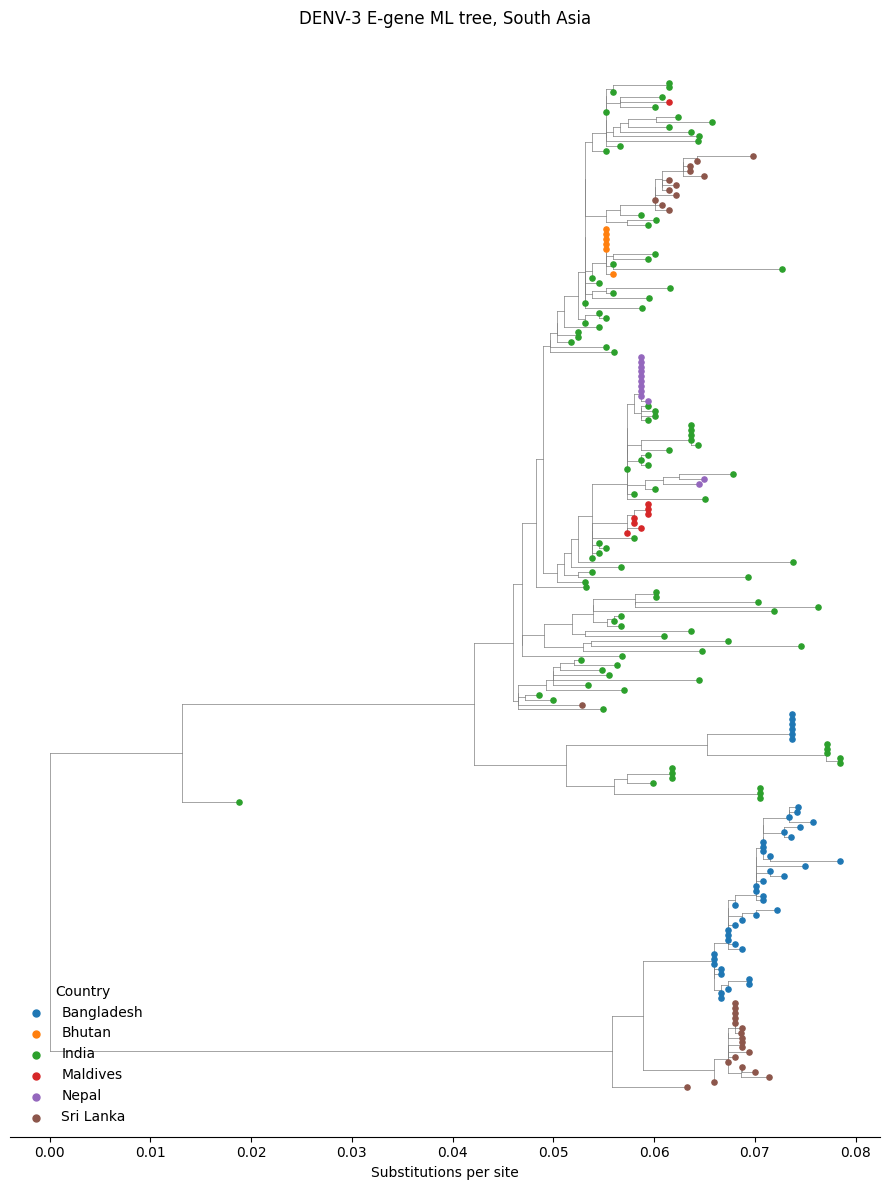

In [9]:
# Tree figure colored by country
meta = sub.set_index("acc")
countries = sorted(meta.country.unique())
cmap = dict(zip(countries, plt.cm.tab10(np.arange(len(countries)))))
depths = tree.depths()
tips = tree.get_terminals(); ypos = {t: i for i, t in enumerate(tips)}
def ycoord(c):
    if c.is_terminal(): return ypos[c]
    ys = [ycoord(k) for k in c.clades]; ypos[c] = np.mean(ys); return ypos[c]
ycoord(tree.root)
fig, ax = plt.subplots(figsize=(9, 12))
def draw(c):
    for k in c.clades:
        ax.plot([depths[c], depths[k]], [ypos[k], ypos[k]], color="0.5", lw=0.5)
        draw(k)
    if c.clades:
        ys = [ypos[k] for k in c.clades]
        ax.plot([depths[c], depths[c]], [min(ys), max(ys)], color="0.5", lw=0.5)
draw(tree.root)
for t in tips:
    ax.scatter(depths[t], ypos[t], s=14, color=cmap[meta.loc[t.name, "country"]], zorder=3)
for c in countries: ax.scatter([], [], color=cmap[c], label=c, s=25)
ax.legend(title="Country", loc="lower left", frameon=False)
ax.set_yticks([]); ax.set_xlabel("Substitutions per site")
ax.set_title(f"{SEROTYPE} E-gene ML tree, South Asia")
for s_ in ["top", "right", "left"]: ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT}/fig_tree_{SEROTYPE}.png", dpi=300); plt.show()

In [10]:
# Patristic distance matrix and Fitch parsimony
names = [t.name for t in tips]; n = len(names)
paths = {}
def walk(c, p):
    p = p + [c]
    if c.is_terminal(): paths[c.name] = p
    for k in c.clades: walk(k, p)
walk(tree.root, [])
D = np.zeros((n, n))
for i in range(n):
    pi = paths[names[i]]
    for j in range(i + 1, n):
        pj = paths[names[j]]
        k = 0
        while k < min(len(pi), len(pj)) and pi[k] is pj[k]: k += 1
        lca = pi[k - 1]
        D[i, j] = D[j, i] = depths[tips[i]] + depths[tips[j]] - 2 * depths[lca]
lab = np.array([meta.loc[x, "country"] for x in names])

def fitch(labels):
    cost = 0
    def rec(c):
        nonlocal cost
        if c.is_terminal(): return {labels[c.name]}
        sets = [rec(k) for k in c.clades]
        inter = set.intersection(*sets)
        if inter: return inter
        cost += 1; return set.union(*sets)
    rec(tree.root); return cost
lab_d = dict(zip(names, lab))
obs_changes = fitch(lab_d)
null_changes = []
for _ in range(500):
    perm = np.random.permutation(lab); null_changes.append(fitch(dict(zip(names, perm))))
print("Fitch country changes: observed", obs_changes, "| null mean", np.mean(null_changes),
      "| p(null<=obs) =", (np.sum(np.array(null_changes) <= obs_changes) + 1) / 501)

Fitch country changes: observed 12 | null mean 93.872 | p(null<=obs) = 0.001996007984031936


      country    n  within_mean  null_mean  p_value
0  Bangladesh   46       0.0375     0.0673    0.002
1      Bhutan    6       0.0002     0.0676    0.002
2       India  103       0.0264     0.0674    0.002
3    Maldives    8       0.0067     0.0669    0.002
4       Nepal   12       0.0029     0.0678    0.002
5   Sri Lanka   31       0.0683     0.0673    0.499


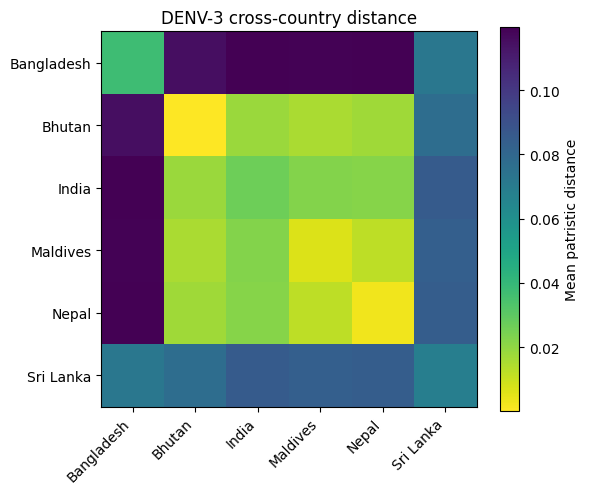

In [11]:
# Within-country distance vs permutation null; cross-country distance matrix
def within(l, c):
    idx = np.where(l == c)[0]
    if len(idx) < 3: return np.nan
    sub_ = D[np.ix_(idx, idx)]; return sub_[np.triu_indices(len(idx), 1)].mean()
res = []
for c in countries:
    o = within(lab, c)
    if np.isnan(o): continue
    nul = np.array([within(np.random.permutation(lab), c) for _ in range(500)])
    res.append((c, int((lab == c).sum()), o, nul.mean(), (np.sum(nul <= o) + 1) / 501))
wt = pd.DataFrame(res, columns=["country", "n", "within_mean", "null_mean", "p_value"]).round(4)
wt.to_csv(f"{OUT}/table_within_country_{SEROTYPE}.csv", index=False); print(wt)

M = pd.DataFrame(index=countries, columns=countries, dtype=float)
for a in countries:
    for b in countries:
        ia, ib = np.where(lab == a)[0], np.where(lab == b)[0]
        sm = D[np.ix_(ia, ib)]
        M.loc[a, b] = sm[sm > 0].mean() if (a != b) else within(lab, a)
M.round(4).to_csv(f"{OUT}/table_between_country_dist_{SEROTYPE}.csv")
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(M.values.astype(float), cmap="viridis_r")
ax.set_xticks(range(len(countries))); ax.set_xticklabels(countries, rotation=45, ha="right")
ax.set_yticks(range(len(countries))); ax.set_yticklabels(countries)
plt.colorbar(im, label="Mean patristic distance"); ax.set_title(f"{SEROTYPE} cross-country distance")
plt.tight_layout(); plt.savefig(f"{OUT}/fig_country_dist_{SEROTYPE}.png", dpi=300); plt.show()

In [12]:
# Lineage-level check: does each lineage form one clade with high support?
lin = meta.loc[names, "lineage"].values
rows = []
for L in sorted(set(lin)):
    idx = np.where(lin == L)[0]
    if len(idx) < 3: continue
    o = D[np.ix_(idx, idx)][np.triu_indices(len(idx), 1)].mean()
    rows.append((L, len(idx), round(o, 4), ", ".join(sorted(set(lab[idx])))))
lt = pd.DataFrame(rows, columns=["lineage", "n", "mean_within_dist", "countries"])
lt.to_csv(f"{OUT}/table_lineage_{SEROTYPE}.csv", index=False); print(lt)
shutil.make_archive("denv_phylo_" + SEROTYPE, "zip", OUT)
print("zipped ->", "denv_phylo_" + SEROTYPE + ".zip")

      lineage   n  mean_within_dist                           countries
0        3III   7            0.0124                               India
1      3III_A  11            0.0116                   Bangladesh, India
2      3III_B  11            0.0285                               India
3    3III_B.3  70            0.0157  Bhutan, India, Maldives, Sri Lanka
4  3III_B.3.1  47            0.0100              India, Maldives, Nepal
5    3I_A.1.1  17            0.0024                           Sri Lanka
6      3I_A.2  40            0.0054                          Bangladesh
zipped -> denv_phylo_DENV-3.zip
